<a href="https://colab.research.google.com/github/jelianeys21/procesamiento-imagenes/blob/main/S7_PDIYVA_dilatacion-erocion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
!git clone https://github.com/giancarlo92/curso_pdi

Cloning into 'curso_pdi'...
remote: Enumerating objects: 83, done.
remote: Counting objects: 100% (83/83), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 83 (delta 21), reused 21 (delta 1), pack-reused 0
Unpacking objects: 100% (83/83), done.


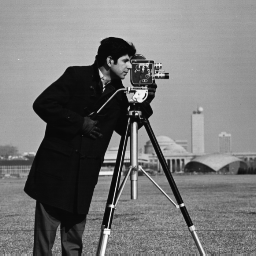

In [ ]:
imagen_gris = cv2.imread("/content/curso_pdi/imagenes/clase7/cameraman.png", 0)
cv2_imshow(imagen_gris)

**DILATACION**

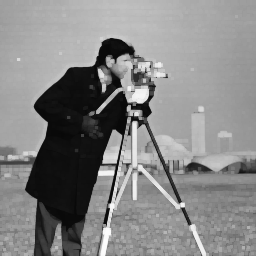

In [ ]:
import math
#256x256
#259x259
#256x256
#253x253
elemento_estructural = np.ones((3, 3), np.uint8)
(fs, cs) = elemento_estructural.shape
fss = fs/2
css= cs/2
# redondeos
fss2= math.floor(fss)
css2 = math.floor(css)
fss1 = math.ceil(fss)
css1 = math.ceil(css)
#dimension de la imagen_gris
(fi, ci) = imagen_gris.shape
#dimension de la imagen ampliada
f = fi + fss2 + fss1
c = ci + css2 + css1
# ampliando la imagen
imagen_ampliada = np.zeros((f, c))
imagen_ampliada[fss2:f-fss1, css2:c-css1] = imagen_gris
dilat = np.zeros((fi, ci), np.uint8)
# aplicar la tecnica de dilatacion
for i in range(0, fi):
  for j in range(0, ci):
    # una porcion segun el elemento estructural
    I1 = imagen_ampliada[i:fs+i, j:cs+j]
    I2 = I1*elemento_estructural
    dilat[i][j] = I2.max()
cv2_imshow(dilat)

**EROSION**

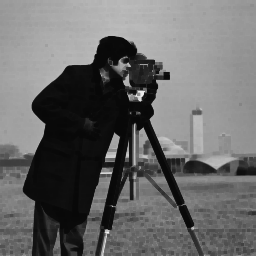

In [ ]:
import math
elemento_estructural = np.ones((3, 3), np.uint8)
(fs, cs) = elemento_estructural.shape
fss = fs/2
css= cs/2
# redondeos
fss2= math.floor(fss)
css2 = math.floor(css)
fss1 = math.ceil(fss)
css1 = math.ceil(css)
#dimension de la imagen_gris
(fi, ci) = imagen_gris.shape
#dimension de la imagen ampliada
f = fi + fss2 + fss1
c = ci + css2 + css1
# ampliando la imagen
imagen_ampliada = 255 * np.ones((f, c))
imagen_ampliada[fss2:f-fss1, css2:c-css1] = imagen_gris
eros = np.zeros((fi, ci), np.uint8)
# aplicar la tecnica de erosacion
for i in range(0, fi):
  for j in range(0, ci):
    # una porcion segun el elemento estructural
    I1 = imagen_ampliada[i:fs+i, j:cs+j]
    I2 = I1*elemento_estructural
    eros[i][j] = I2.min()
cv2_imshow(eros)

**OPENCV**

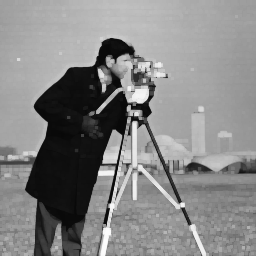

In [ ]:
EE =np.ones((3, 3), np.uint8)
dilatacion_opencv = cv2.dilate(imagen_gris, EE, iterations=1)
cv2_imshow(dilatacion_opencv)

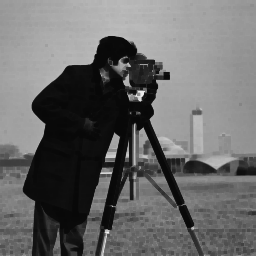

In [ ]:
EE =np.ones((3, 3), np.uint8)
erosion_opencv = cv2.erode(imagen_gris, EE, iterations=1)
cv2_imshow(erosion_opencv)

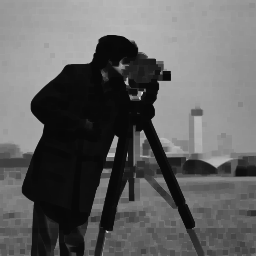

In [ ]:
from curso_pdi.funciones.erosion import erosion
EE = np.ones((5,5), np.uint8)
erosionando = erosion(imagen_gris, EE)
cv2_imshow(erosionando)

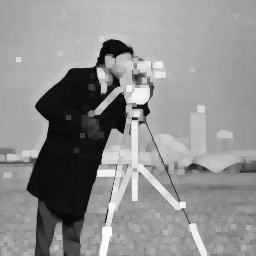

In [ ]:
from curso_pdi.funciones.dilatacion import dilatacion
EE = np.ones((5,5), np.uint8)
dilatando = dilatacion(imagen_gris, EE)
cv2_imshow(dilatando)